Please upload the input image:


Saving sunset.jpg to sunset.jpg


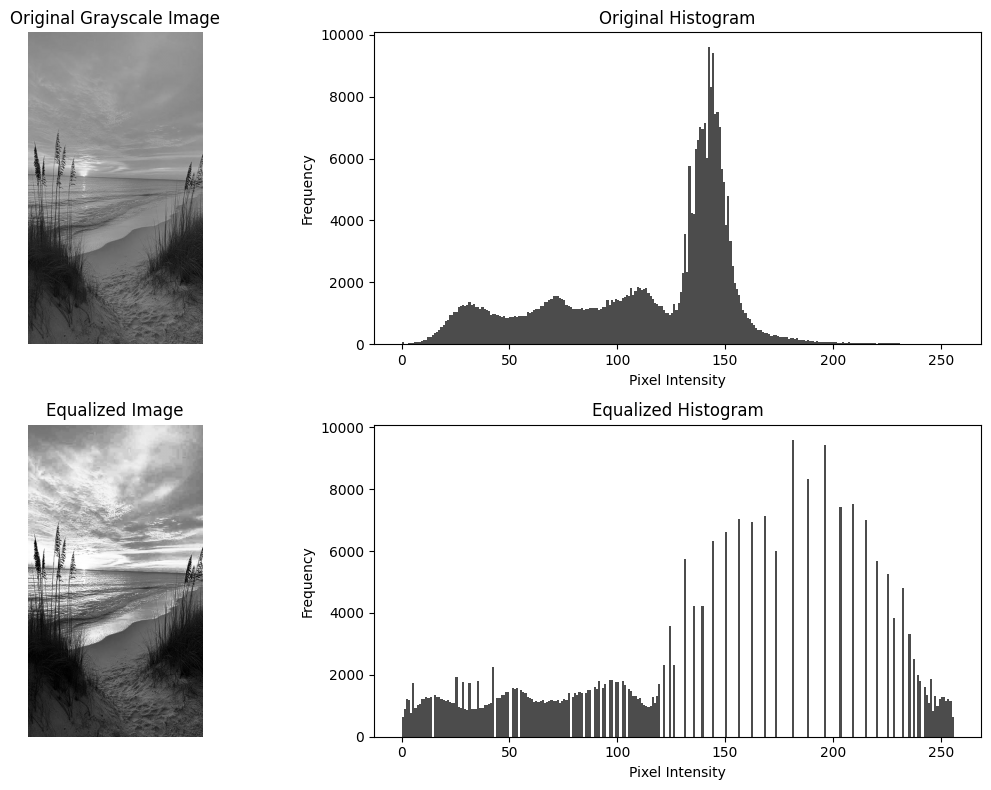

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files
print("Please upload the input image:")
uploaded = files.upload()
filename = list(uploaded.keys())[0]

img_gray = cv2.imread(filename, cv2.IMREAD_GRAYSCALE)

equalized_img = cv2.equalizeHist(img_gray)

plt.figure(figsize=(12, 8))

plt.subplot(2, 2, 1)
plt.imshow(img_gray, cmap='gray')
plt.title('Original Grayscale Image')
plt.axis('off')

plt.subplot(2, 2, 2)
plt.hist(img_gray.ravel(), bins=256, range=[0, 256], color='black', alpha=0.7)
plt.title('Original Histogram')
plt.xlabel('Pixel Intensity')
plt.ylabel('Frequency')

plt.subplot(2, 2, 3)
plt.imshow(equalized_img, cmap='gray')
plt.title('Equalized Image')
plt.axis('off')

plt.subplot(2, 2, 4)
plt.hist(equalized_img.ravel(), bins=256, range=[0, 256], color='black', alpha=0.7)
plt.title('Equalized Histogram')
plt.xlabel('Pixel Intensity')
plt.ylabel('Frequency')

plt.tight_layout()
plt.show()

Upload the INPUT / SOURCE image:


Saving sunset.jpg to sunset (1).jpg

Upload the REFERENCE image:


Saving download.png to download.png


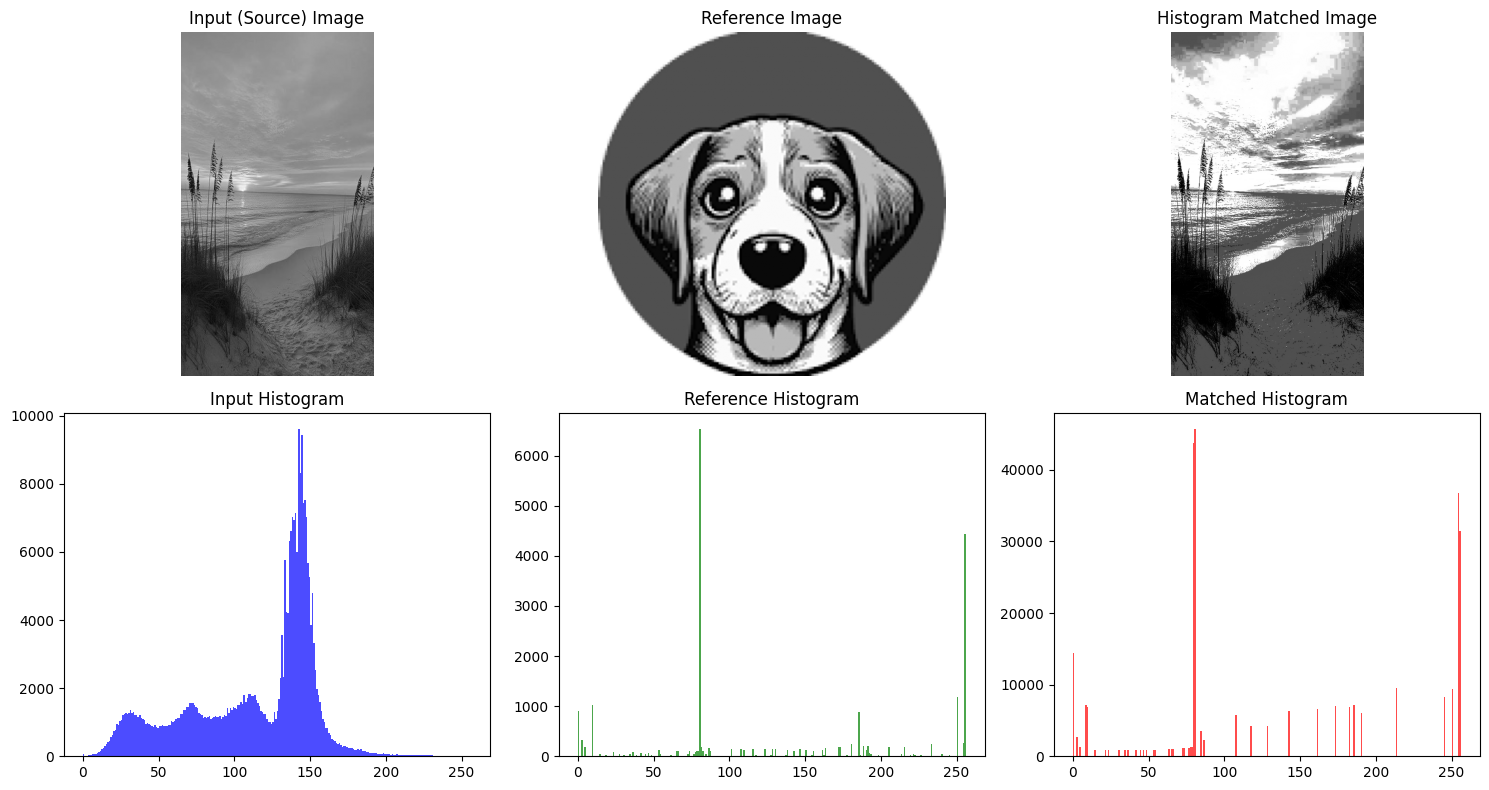

In [2]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files

def histogram_matching(source, reference):
    hist_src, _ = np.histogram(source.flatten(), 256, [0, 256])
    hist_ref, _ = np.histogram(reference.flatten(), 256, [0, 256])

    cdf_src = hist_src.cumsum()
    cdf_src_normalized = cdf_src / cdf_src[-1]

    cdf_ref = hist_ref.cumsum()
    cdf_ref_normalized = cdf_ref / cdf_ref[-1]


    mapping = np.zeros(256, dtype=np.uint8)
    for src_val in range(256):
        diff = np.abs(cdf_src_normalized[src_val] - cdf_ref_normalized)
        mapping[src_val] = np.argmin(diff)

    matched = mapping[source]
    return matched

print("Upload the INPUT / SOURCE image:")
uploaded_src = files.upload()
src_filename = list(uploaded_src.keys())[0]

print("\nUpload the REFERENCE image:")
uploaded_ref = files.upload()
ref_filename = list(uploaded_ref.keys())[0]

img_src = cv2.imread(src_filename, cv2.IMREAD_GRAYSCALE)
img_ref = cv2.imread(ref_filename, cv2.IMREAD_GRAYSCALE)

matched_img = histogram_matching(img_src, img_ref)

plt.figure(figsize=(15, 8))

plt.subplot(2, 3, 1)
plt.imshow(img_src, cmap='gray')
plt.title('Input (Source) Image')
plt.axis('off')

plt.subplot(2, 3, 4)
plt.hist(img_src.ravel(), bins=256, range=[0, 256], color='blue', alpha=0.7)
plt.title('Input Histogram')

plt.subplot(2, 3, 2)
plt.imshow(img_ref, cmap='gray')
plt.title('Reference Image')
plt.axis('off')

plt.subplot(2, 3, 5)
plt.hist(img_ref.ravel(), bins=256, range=[0, 256], color='green', alpha=0.7)
plt.title('Reference Histogram')

plt.subplot(2, 3, 3)
plt.imshow(matched_img, cmap='gray')
plt.title('Histogram Matched Image')
plt.axis('off')

plt.subplot(2, 3, 6)
plt.hist(matched_img.ravel(), bins=256, range=[0, 256], color='red', alpha=0.7)
plt.title('Matched Histogram')

plt.tight_layout()
plt.show()